<a href="https://colab.research.google.com/github/saran-shams/Classic_CV/blob/main/ObjectDectection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Question 1 Final Tuned Parameters ---
dp=1, minDist=40, param1=50, param2=35, minRadius=10, maxRadius=120

Detected Circles:


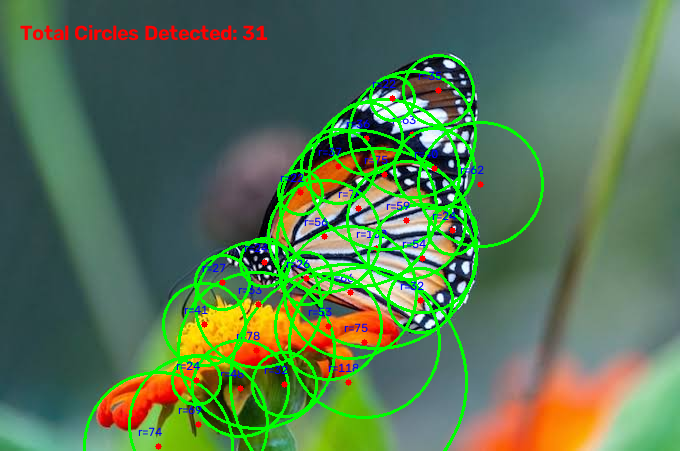

--- Question 2 Performance Metrics ---
Total lines detected by Standard Hough (cv2.HoughLines): 40
Total lines detected by Probabilistic Hough (cv2.HoughLinesP): 211

Standard Hough Lines (Red):


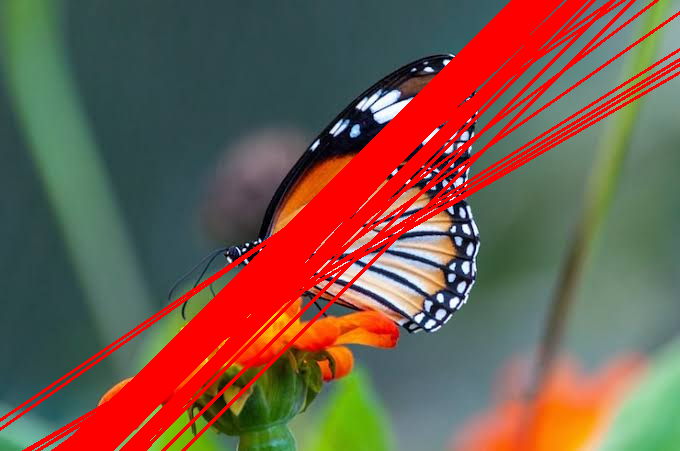

Probabilistic Hough Lines (Green):


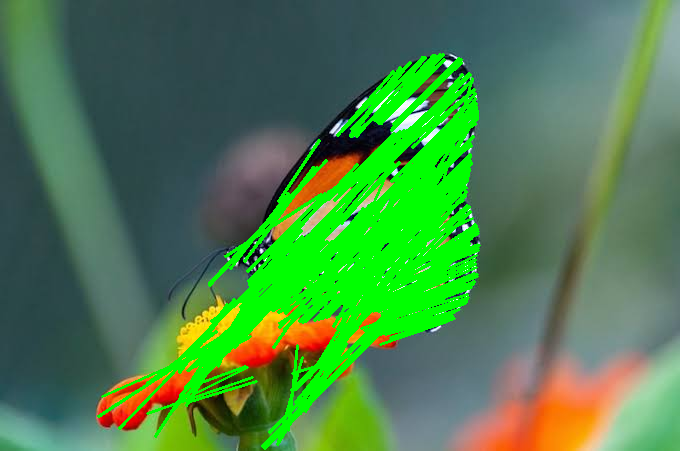

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# QUESTION 1:
def detect_and_label_circles(image_path):
    img = cv2.imread(image_path)
    if img is None:
        print(f"Error: Could not load image from {image_path}")
        return

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    gray_blurred = cv2.medianBlur(gray, 5)

    dp_val = 1
    min_dist_val = 40
    p1 = 50
    p2 = 35
    min_r = 10
    max_r = 120

    circles = cv2.HoughCircles(
        gray_blurred,
        cv2.HOUGH_GRADIENT,
        dp=dp_val,
        minDist=min_dist_val,
        param1=p1,
        param2=p2,
        minRadius=min_r,
        maxRadius=max_r
    )

    total_circles = 0
    if circles is not None:
        circles = np.uint16(np.around(circles))
        total_circles = len(circles[0])

        for i in circles[0]:
            center = (i[0], i[1])
            radius = i[2]

            cv2.circle(img, center, radius, (0, 255, 0), 2)
            cv2.circle(img, center, 3, (0, 0, 255), -1)
            cv2.putText(img, f"r={radius}", (i[0] - 20, i[1] - 10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1)

    cv2.putText(img, f"Total Circles Detected: {total_circles}", (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)

    print(f"--- Question 1 Final Tuned Parameters ---")
    print(f"dp={dp_val}, minDist={min_dist_val}, param1={p1}, param2={p2}, minRadius={min_r}, maxRadius={max_r}\n")

    print("Detected Circles:")
    cv2_imshow(img)


# QUESTION 2:
def detect_road_lanes(image_path):
    img = cv2.imread(image_path)
    if img is None:
        print(f"Error: Could not load image from {image_path}")
        return

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray, 50, 150, apertureSize=3)

    img_standard = img.copy()
    img_probabilistic = img.copy()

    lines_standard = cv2.HoughLines(edges, rho=1, theta=np.pi/180, threshold=120)
    count_standard = 0

    if lines_standard is not None:
        count_standard = len(lines_standard)
        for line in lines_standard:
            rho, theta = line[0]
            a = np.cos(theta)
            b = np.sin(theta)
            x0 = a * rho
            y0 = b * rho
            x1 = int(x0 + 1000 * (-b))
            y1 = int(y0 + 1000 * (a))
            x2 = int(x0 - 1000 * (-b))
            y2 = int(y0 - 1000 * (a))
            cv2.line(img_standard, (x1, y1), (x2, y2), (0, 0, 255), 2)

    lines_prob = cv2.HoughLinesP(edges, rho=1, theta=np.pi/180, threshold=50,
                                 minLineLength=60, maxLineGap=15)
    count_prob = 0

    if lines_prob is not None:
        count_prob = len(lines_prob)
        for line in lines_prob:
            coords = line.ravel()
            if len(coords) == 4:
                x1, y1, x2, y2 = coords
                cv2.line(img_probabilistic, (x1, y1), (x2, y2), (0, 255, 0), 2)

    print("--- Question 2 Performance Metrics ---")
    print(f"Total lines detected by Standard Hough (cv2.HoughLines): {count_standard}")
    print(f"Total lines detected by Probabilistic Hough (cv2.HoughLinesP): {count_prob}\n")

    print("Standard Hough Lines (Red):")
    cv2_imshow(img_standard)
    print("Probabilistic Hough Lines (Green):")
    cv2_imshow(img_probabilistic)

if __name__ == "__main__":
    detect_and_label_circles("imag.jpeg")
    detect_road_lanes("imag.jpeg")

Reasons:

• Finite Line Segments: cv2.HoughLines calculates infinite lines that cover the coordinate system with the hough space \((\rho, \theta)\), which is unable to identify a start point or an end point of a specific line on the image. However, the function cv2.HoughLinesP can return the concrete coordinate of line segments \((x_1, y_1, x_2, y_2)\).

• Gap and Length Parameters: This function provides users with two parameters, minLineLength and maxLineGap, so that the broken lines can be connected based on the specific requirements. In this way, not only the dashed lines are removed, but also the line segments outside the target range are screened out.

• Algorithmic Efficiency: The function makes calculations on a randomly selected part of the coordinate matrix, which makes contribution to noise removal of the background grid and irrelevant objects.